# Clustering des pages du Soir, années 1940

## Imports

In [1]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency
import seaborn as sns

In [2]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DERRICK\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
data_path =  "../../data/txt/"

## Choisir une décennie

In [4]:
DECADE = '1940'

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [5]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [6]:
# Exemple de fichiers
files[:5]

['KB_JB838_1940-01-04_01-00001.txt',
 'KB_JB838_1940-01-05_01-00009.txt',
 'KB_JB838_1940-01-07_01-00014.txt',
 'KB_JB838_1940-01-10_01-00003.txt',
 'KB_JB838_1940-01-11_01-00004.txt']

In [7]:
texts = []
for f in files:
    with open(data_path + f, "r", encoding="utf-8") as fh:
        texts.append(fh.read())
len(texts)

1000

In [8]:
# Exemple de textes
texts[0][:400]

"54 e ANNEE. — N° 4. Pages - 40 C 1 *® 8 Grand-Duché : 45 centimes. - France : 75 centime». ABONNEMENTS pour la province on Province } s'abonne à là Poste CH' Vüle au $ pour | T , oi , ŒOl# 28>50 BUREAUX ET FILS SPÉCIAUX: — — ■ ; S Un an 170.00 Congo • j Six mol , 85X0 Etranger : Prix euivant conventions VENTE ET ABONNEM. : PLACE DE LOUVAIN. 23 □ SALLE DE DÉPÊCHES : 124. RUE ROYALE BRUXELLES G “ ■“"

## Vectoriser les documents à l'aide de TF-IDF

In [9]:
# Création d'une fonction de pré-traitement
def preprocessing(text):
    """Découpe le texte en mots après avoir retiré la ponctuation"""
    punctuation = string.punctuation + "’‘«»“”—–…°®•"
    text = text.translate(str.maketrans('', '', punctuation))
    tokens = word_tokenize(text, language='french')
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [10]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [11]:
tfidf_vectors = vectorizer.fit_transform(texts)

c:\Users\DERRICK\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [12]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 940483 stored elements and shape (1000, 4613)>

### Imprimer le vecteur tf-IDF du premier document

In [13]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

gouvernement    0.158981
milieux         0.155027
cabinet         0.133183
litalie         0.126929
neige           0.118391
                  ...   
107             0.000000
106             0.000000
1050            0.000000
105             0.000000
05              0.000000
Length: 4613, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [14]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [15]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [16]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [17]:
tfidf_array = tfidf_vectors.toarray()

In [18]:
# Vecteur du document 0
tfidf_array[0]

array([0.01764576, 0.        , 0.        , ..., 0.        , 0.        ,
       0.        ], shape=(4613,))

In [19]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.        , 0.        , ..., 0.00663599, 0.00738525,
       0.        ], shape=(4613,))

In [20]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.9508306242957922)

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Choisir le nombre de clusters

Je teste les valeurs de 2 à 12 et je compare deux mesures qui sont l'inertie (méthode du coude) et le score de silhouette.

In [21]:
# Mesurer la qualité du clustering pour chaque nombre de clusters
scores = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(tfidf_vectors)
    scores.append({
        "k": k,
        "inertie": km.inertia_,
        "silhouette": silhouette_score(tfidf_vectors, labels_k),
    })
scores_df = pd.DataFrame(scores)
scores_df

,k,inertie,silhouette
0,2,757.213134,0.102326
1,3,725.512078,0.097958
2,4,703.894410,0.089206
3,5,687.329127,0.093744
4,6,675.602907,0.077901
5,7,660.480776,0.081870
6,8,646.245605,0.080656
7,9,637.094577,0.082320
8,10,632.004879,0.075649
9,11,626.182740,0.077748


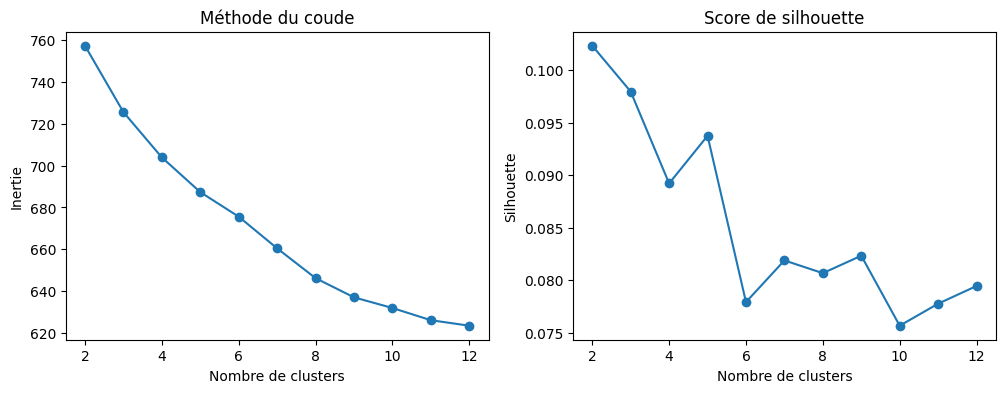

In [22]:
# Méthode du coude et score de silhouette
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(scores_df["k"], scores_df["inertie"], marker="o")
ax1.set_title("Méthode du coude")
ax1.set_xlabel("Nombre de clusters")
ax1.set_ylabel("Inertie")
ax2.plot(scores_df["k"], scores_df["silhouette"], marker="o")
ax2.set_title("Score de silhouette")
ax2.set_xlabel("Nombre de clusters")
ax2.set_ylabel("Silhouette")
plt.show()

### Définir un nombre de clusters

In [23]:
N_CLUSTERS = 8

### Instancier le modèle K-Means et ses arguments

In [24]:
km_model = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [25]:
clusters = km_model.fit_predict(tfidf_vectors)

In [26]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [27]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1940-01-04_01-00001.txt',
               'KB_JB838_1940-01-11_01-00004.txt',
               'KB_JB838_1940-01-27_01-00004.txt',
               'KB_JB838_1940-01-31_01-00002.txt',
               'KB_JB838_1940-02-07_01-00004.txt',
               'KB_JB838_1940-02-18_01-00014.txt',
               'KB_JB838_1940-02-25_01-00006.txt',
               'KB_JB838_1940-02-29_01-00005.txt',
               'KB_JB838_1940-03-03_01-00004.txt',
               'KB_JB838_1940-03-31_01-00002.txt',
               'KB_JB838_1940-04-19_01-00004.txt',
               'KB_JB838_1940-04-29_01-00001.txt',
               'KB_JB838_1940-05-02_01-00002.txt',
               'KB_JB838_1940-05-02_01-00004.txt',
               'KB_JB838_1940-06-19_01-00002.txt',
               'KB_JB838_1940-07-16_01-00001.txt',
               'KB_JB838_1940-07-21_01-00005.txt',
               'KB_JB838_1940-07-22_01-00006.txt',
               'KB_JB838_1940-07-24_01-00001.txt',
               'KB_JB838_1940-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [28]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [29]:
reduced_vectors[:10]

array([[-0.25984243,  0.16489527],
       [ 0.61807599,  0.18997726],
       [ 0.11269759, -0.07913249],
       [-0.29866139,  0.28004242],
       [-0.26240906,  0.11728428],
       [-0.19361525, -0.15157684],
       [-0.27928356,  0.17746234],
       [-0.25954733,  0.14848394],
       [-0.11527349, -0.17584421],
       [ 0.45227659,  0.04090499]])

### Générer le plot

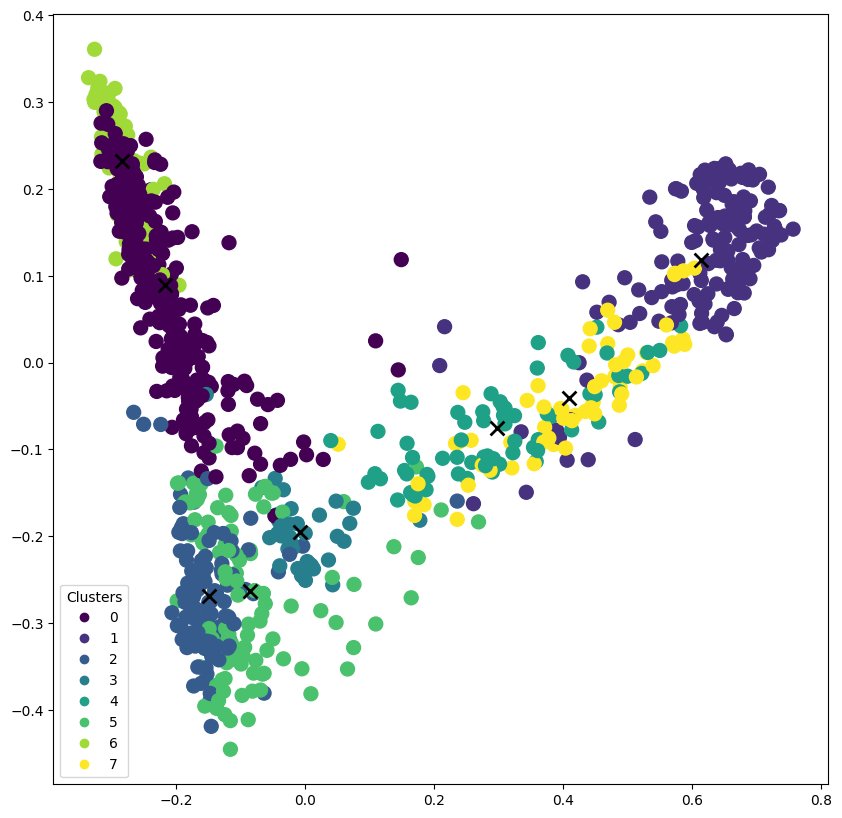

In [30]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

## Interpréter les clusters

Pour chaque cluster, j'affiche son nombre de pages, les 15 mots qui pèsent le plus dans son centre, puis la répartition de ses pages par année.

In [31]:
# Nombre de pages et mots les plus caractéristiques de chaque cluster
terms = vectorizer.get_feature_names_out()
counts = collections.Counter(clusters)

for i, center in enumerate(km_model.cluster_centers_):
    top = center.argsort()[::-1][:15]
    print(f"Cluster {i} ({counts[i]} pages) :", ", ".join(terms[j] for j in top))

Cluster 0 (320 pages) : ministre, gouvernement, politique, commission, allemands, etatsunis, projet, parti, juin, conférence, janvier, novembre, août, économique, lallemagne
Cluster 1 (147 pages) : dem, rossel, ag, ecr, ecrire, ec, ecagrossel, trav, agrossel, cherche, réf, agence, référ, mod, app
Cluster 2 (120 pages) : match, course, bat, division, mètres, mutuel, points, classement, pts, championnat, équipes, champion, vainqueur, léquipe, finale
Cluster 3 (39 pages) : notaire, ca, etude, faç, visites, lot, cont, rentier, jardin, commune, étages, ares, façade, létude, vendra
Cluster 4 (69 pages) : vend, hp, ag, rossel, vendre, ford, cv, ecr, z, ecrire, chevrolet, pneus, cyl, renault, ec
Cluster 5 (112 pages) : ps, cap, mod, admis, katanga, ord, 250, dette, oo, argent, pf, enf, congo, valeurs, dannoncer
Cluster 6 (133 pages) : troupes, front, gouvernement, forces, allemands, berlin, combats, allemandes, politique, allemande, ministre, allemand, attaques, lennemi, combat
Cluster 7 (60 p

In [32]:
# Répartition des pages de chaque cluster par année
for i in range(N_CLUSTERS):
    years = collections.Counter(files[j].split('_')[2][:4] for j in range(len(files)) if clusters[j] == i)
    print(f"Cluster {i} :", dict(sorted(years.items())))

Cluster 0 : {'1940': 41, '1941': 31, '1942': 9, '1943': 12, '1944': 14, '1945': 52, '1946': 39, '1947': 41, '1948': 40, '1949': 41}
Cluster 1 : {'1940': 9, '1941': 9, '1942': 16, '1943': 10, '1944': 17, '1945': 31, '1946': 12, '1947': 19, '1948': 15, '1949': 9}
Cluster 2 : {'1940': 15, '1941': 13, '1942': 18, '1943': 13, '1944': 5, '1945': 2, '1946': 9, '1947': 16, '1948': 11, '1949': 18}
Cluster 3 : {'1940': 5, '1941': 5, '1942': 5, '1943': 5, '1944': 6, '1945': 5, '1946': 4, '1948': 2, '1949': 2}
Cluster 4 : {'1940': 7, '1941': 8, '1944': 1, '1946': 12, '1947': 16, '1948': 12, '1949': 13}
Cluster 5 : {'1940': 7, '1941': 14, '1942': 14, '1943': 30, '1944': 12, '1945': 2, '1946': 14, '1947': 4, '1948': 9, '1949': 6}
Cluster 6 : {'1940': 8, '1941': 14, '1942': 36, '1943': 30, '1944': 42, '1945': 3}
Cluster 7 : {'1940': 8, '1941': 6, '1942': 2, '1944': 3, '1945': 5, '1946': 10, '1947': 4, '1948': 11, '1949': 11}


## Les clusters au fil des années

Je regarde comment les pages de chaque cluster se répartissent selon leur année de publication. Un test du khi-deux me permet ensuite de vérifier si cette répartition change vraiment d'une année à l'autre, ou si les écarts pourraient être dus au hasard.

In [33]:
# Nombre de pages de chaque cluster pour chaque année
years = [f.split('_')[2][:4] for f in files]
tableau = pd.crosstab(pd.Series(clusters, name="Cluster"), pd.Series(years, name="Année"))
tableau

Année,1940,1941,1942,1943,1944,1945,1946,1947,1948,1949
Cluster,,,,,,,,,,
0,41,31,9,12,14,52,39,41,40,41
1,9,9,16,10,17,31,12,19,15,9
2,15,13,18,13,5,2,9,16,11,18
3,5,5,5,5,6,5,4,0,2,2
4,7,8,0,0,1,0,12,16,12,13
5,7,14,14,30,12,2,14,4,9,6
6,8,14,36,30,42,3,0,0,0,0
7,8,6,2,0,3,5,10,4,11,11


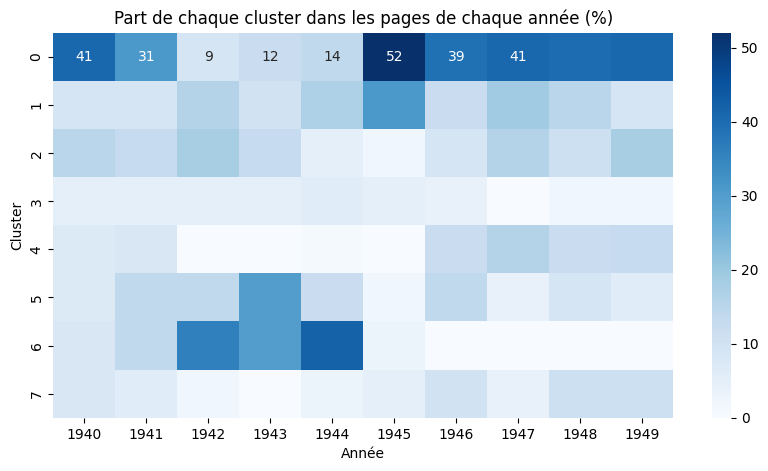

In [34]:
# Part de chaque cluster dans les pages de chaque année (en %)
pourcentages = pd.crosstab(pd.Series(clusters, name="Cluster"), pd.Series(years, name="Année"), normalize="columns") * 100

plt.figure(figsize=(10, 5))
sns.heatmap(pourcentages, annot=True, fmt=".0f", cmap="Blues")
plt.title("Part de chaque cluster dans les pages de chaque année (%)")
plt.show()

In [35]:
# Test du khi-deux : la répartition des clusters dépend-elle de l'année ?
chi2, p_value, dof, expected = chi2_contingency(tableau)
print(f"Khi-deux = {chi2:.1f}, degrés de liberté = {dof}, p-value = {p_value:.2e}")
print(f"Cases dont l'effectif attendu est inférieur à 5 : {(expected < 5).sum()} sur {expected.size}")

Khi-deux = 430.0, degrés de liberté = 63, p-value = 4.61e-56
Cases dont l'effectif attendu est inférieur à 5 : 10 sur 80


## Les mots-clés de chaque cluster, d'un à trois mots

Les mots isolés ne suffisent pas toujours à comprendre un cluster. Je cherche donc aussi les expressions de deux et trois mots qui le caractérisent le mieux.

In [36]:
# Expressions d'un, deux et trois mots les plus caractéristiques de chaque cluster
ngram_vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    ngram_range=(1, 3),
    min_df=10,
    max_df=0.5,
    lowercase=True)
ngram_vectors = ngram_vectorizer.fit_transform(texts)
ngram_terms = ngram_vectorizer.get_feature_names_out()
ngram_sizes = np.array([len(t.split()) for t in ngram_terms])

for i in range(N_CLUSTERS):
    mean_scores = np.asarray(ngram_vectors[clusters == i].mean(axis=0)).ravel()
    order = mean_scores.argsort()[::-1]
    print(f"Cluster {i} ({counts[i]} pages)")
    for n, name in [(1, "unigrammes"), (2, "bigrammes"), (3, "trigrammes")]:
        best = [ngram_terms[j] for j in order if ngram_sizes[j] == n][:8]
        print(f"  {name} : {', '.join(best)}")

c:\Users\DERRICK\tac\.venv\Lib\site-packages\sklearn\feature_extraction\text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Cluster 0 (320 pages)
  unigrammes : ministre, gouvernement, politique, commission, projet, allemands, etatsunis, juin
  bigrammes : a déclaré, a fait, premier ministre, dautre part, quil a, affaires étrangères, sans doute, 20 h
  trigrammes : a f p, prie dannoncer décès, ministre affaires étrangères, sir stafford cripps, place louvain 21, ministre défense nationale, avis tient lieu, royale 124 bruxelles
Cluster 1 (147 pages)
  unigrammes : dem, rossel, ag, ecr, ecrire, ec, ecagrossel, trav
  bigrammes : ag rossel, a v, ecr ag, ecrire ag, ec agrossel, ec ag, agence rossel, a g
  trigrammes : ecr ag rossel, ecrire ag rossel, ec ag rossel, a g rossel, ecrire agence rossel, a lagence rossel, a ag rossel, ag rossel sous
Cluster 2 (120 pages)
  unigrammes : match, course, bat, division, mètres, mutuel, points, championnat
  bigrammes : course prix, division i, van den, non placés, 15 h, 14 h, non pl, vainqueur points
  trigrammes : 14 h 30, g p p, 19 h 30, deuxième course prix, troisième co